In [2]:
from pathlib import Path
import geopandas as gpd

# Works whether the notebook runs from the project root or from notebooks/

ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
BOUND = ROOT / "data" / "raw" / "boundaries"

print("Project root:", ROOT)
print("Boundaries folder exists:", BOUND.exists())
for f in sorted(BOUND.rglob("*.shp")):
    print("  ", f.relative_to(BOUND))

Project root: C:\Users\HP\Documents\Projets\3-Cameroon Broadband Intelligence\cameroon-broadband-intelligence
Boundaries folder exists: True
   cmr_admin0.shp
   cmr_admin0_em.shp
   cmr_admin1.shp
   cmr_admin1_em.shp
   cmr_admin2.shp
   cmr_admin2_em.shp
   cmr_admin3.shp
   cmr_admin3_em.shp
   cmr_admincapitals.shp
   cmr_adminlines.shp
   cmr_adminlines_em.shp
   cmr_adminpoints.shp


In [3]:
regions = gpd.read_file(next(BOUND.rglob("cmr_admin1.shp")))
departments = gpd.read_file(next(BOUND.rglob("cmr_admin2.shp")))

In [4]:
for name, gdf in [("regions", regions), ("departments", departments)]:
    print(f"--- {name} ---")
    print("CRS:", gdf.crs)
    print("Rows, columns:", gdf.shape)
    print("Columns:", list(gdf.columns))
    print()

--- regions ---
CRS: EPSG:4326
Rows, columns: (10, 22)
Columns: ['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry']

--- departments ---
CRS: EPSG:4326
Rows, columns: (58, 27)
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm2_ref_n', 'center_lat', 'center_lon', 'geometry']



In [15]:
departments[departments["adm2_pcode"].isin(["CM005004", "CM002007"])][["adm2_pcode", "adm2_name1"]]

,adm2_pcode,adm2_name1
40,CM002007,Mfoundi
57,CM005004,Wouri


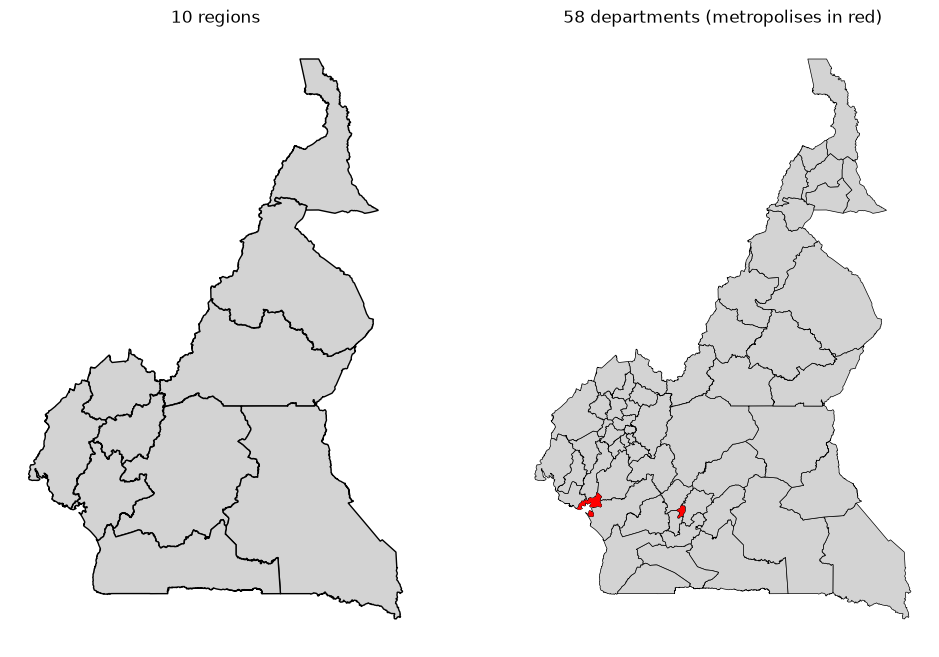

In [5]:
import matplotlib.pyplot as plt

INTERIM = ROOT / "data" / "interim"
reg = gpd.read_file(INTERIM / "regions.geojson")
dep = gpd.read_file(INTERIM / "departments.geojson")

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
reg.plot(ax=axes[0], edgecolor="black", facecolor="lightgrey")
axes[0].set_title("10 regions")

dep.plot(ax=axes[1], edgecolor="black", facecolor="lightgrey", linewidth=0.5)
dep[dep["dept_code"].isin(["CM005004", "CM002007"])].plot(ax=axes[1], color="red")
axes[1].set_title("58 departments (metropolises in red)")

for ax in axes:
    ax.set_axis_off()

(ROOT / "reports").mkdir(exist_ok=True)
fig.savefig(ROOT / "reports" / "boundaries_check.png", dpi=150, bbox_inches="tight")